# Phase 1 (bonus) — Bivariate analysis: what sets apart the customers who leave?

**VIGIE · Group BI 5** — Integrated Project, ESPRIT School of Business · Supervisors: Aymen Ben Brik and Hela Hammami

Every explanatory variable is crossed with churn, **at customer grain** (one customer = one row), on the
319,040 customers holding at least one account.

| Type of variable | Measure of the link | Test |
|---|---|---|
| Qualitative | churn rate per category, **Cramér's V** | χ² test of independence |
| Quantitative | median per class, **univariate AUC** | Mann-Whitney |

With more than 300,000 customers, **every test is significant**: the p-value says nothing useful.
We therefore read the **strength** of the link (Cramér's V, AUC), not only its significance.

*No customer row is displayed: aggregates only.*

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy import stats
from sklearn.metrics import roc_auc_score

ROOT = Path.cwd().resolve().parents[1]
sys.path.insert(0, str(ROOT))
from vigie import config, data, style

warnings.filterwarnings("ignore")
style.apply()
C = config.COLORS
n = style.thousands

df = data.load()
accounts = data.account_grain(df)
customers = data.customer_grain(df, accounts)
ref_date = data.reference_date(df)

base = customers[customers["CHURN"].notna()].copy()
base["CHURN"] = base["CHURN"].astype(int)
base["AGE"] = ref_date.year - (base["BIRTH_PERIOD"] + 2)
base["CUSTOMER_TENURE"] = (ref_date - base["CUST_OPENING_DATE"]).dt.days / 365.25
base["MONTHS_SINCE_REVIEW"] = (ref_date - base["LAST_REVIEW_DATE"]).dt.days / 30.4375
base["MONTHS_TO_NEXT_REVIEW"] = (base["NEXT__REVIEW_DATE"] - ref_date).dt.days / 30.4375
base["FILE_STATUS"] = np.where(base["COMPLETED_FILE"] == "YES", "Complete", "Incomplete")
base["AGE_BAND"] = data.age_band(base["BIRTH_PERIOD"], ref_date.year)
base["TENURE_BAND"] = data.tenure_band(base["CUSTOMER_TENURE"])

overall_rate = base["CHURN"].mean()
print(f"Customers analysed: {n(len(base))}   |   Overall churn rate: {overall_rate:.1%}")

Customers analysed: 319,040   |   Overall churn rate: 36.8%


## 1. Qualitative variables × churn

In [2]:
def cramers_v(x: pd.Series, y: pd.Series) -> tuple[float, float]:
    """Cramér's V (0 = no link, 1 = perfect link) and p-value of the χ² test."""
    table = pd.crosstab(x, y)
    chi2, p, _, _ = stats.chi2_contingency(table)
    total = table.to_numpy().sum()
    return float(np.sqrt(chi2 / (total * (min(table.shape) - 1)))), float(p)


qualitative = {
    "FILE_STATUS": "Customer file", "AGE_BAND": "Age band", "TENURE_BAND": "Tenure band",
    "SCORE_KYC": "KYC score", "BRANCH_GROUP": "Branch group", "MARITAL_STATUS": "Marital status",
    "RESIDENCE_REGION": "Residence zone", "NATIONALITY_REGION": "Nationality zone",
    "NATURE_CLIENT": "Customer type", "PARTYCLASS": "Commercial segment", "LOB": "Line of business",
    "INDUSTRY": "Industry section",
}
rows = []
for col, lab in qualitative.items():
    x = base[col].astype("object").where(base[col].notna(), data.NOT_PROVIDED)
    v, p = cramers_v(x, base["CHURN"])
    per_cat = base.groupby(x)["CHURN"].agg(["mean", "size"])
    per_cat = per_cat[per_cat["size"] >= config.MIN_CELL_SIZE]
    rows.append({
        "Variable": lab, "Categories": x.nunique(), "Cramér's V": round(v, 3), "χ² p-value": f"{p:.1e}",
        "Lowest churn rate": f"{per_cat['mean'].min():.1%} ({per_cat['mean'].idxmin()})",
        "Highest churn rate": f"{per_cat['mean'].max():.1%} ({per_cat['mean'].idxmax()})",
    })
qual_links = pd.DataFrame(rows).set_index("Variable").sort_values("Cramér's V", ascending=False)
display(qual_links)

,Categories,Cramér's V,χ² p-value,Lowest churn rate,Highest churn rate
Variable,,,,,
Customer file,2,0.280,0.0e+00,22.5% (Complete),49.6% (Incomplete)
Tenure band,6,0.156,0.0e+00,8.3% (Under 2 years),45.5% (5–10 years)
Age band,8,0.144,0.0e+00,8.4% (Under 18),44.4% (25–34)
KYC score,6,0.081,0.0e+00,11.9% (Not provided),38.3% (LR)
Branch group,21,0.065,3.1e-273,32.3% (AG05),46.3% (AG06)
Marital status,5,0.043,1.1e-128,29.6% (V),40.9% (D)
Residence zone,6,0.037,1.2e-91,30.2% (AUTRE),49.1% (AFRIQUE_MO)
Nationality zone,6,0.035,5.0e-80,29.6% (AUTRE),47.9% (AFRIQUE_MO)
Customer type,4,0.033,8.1e-75,30.4% (PM),37.2% (PPH)


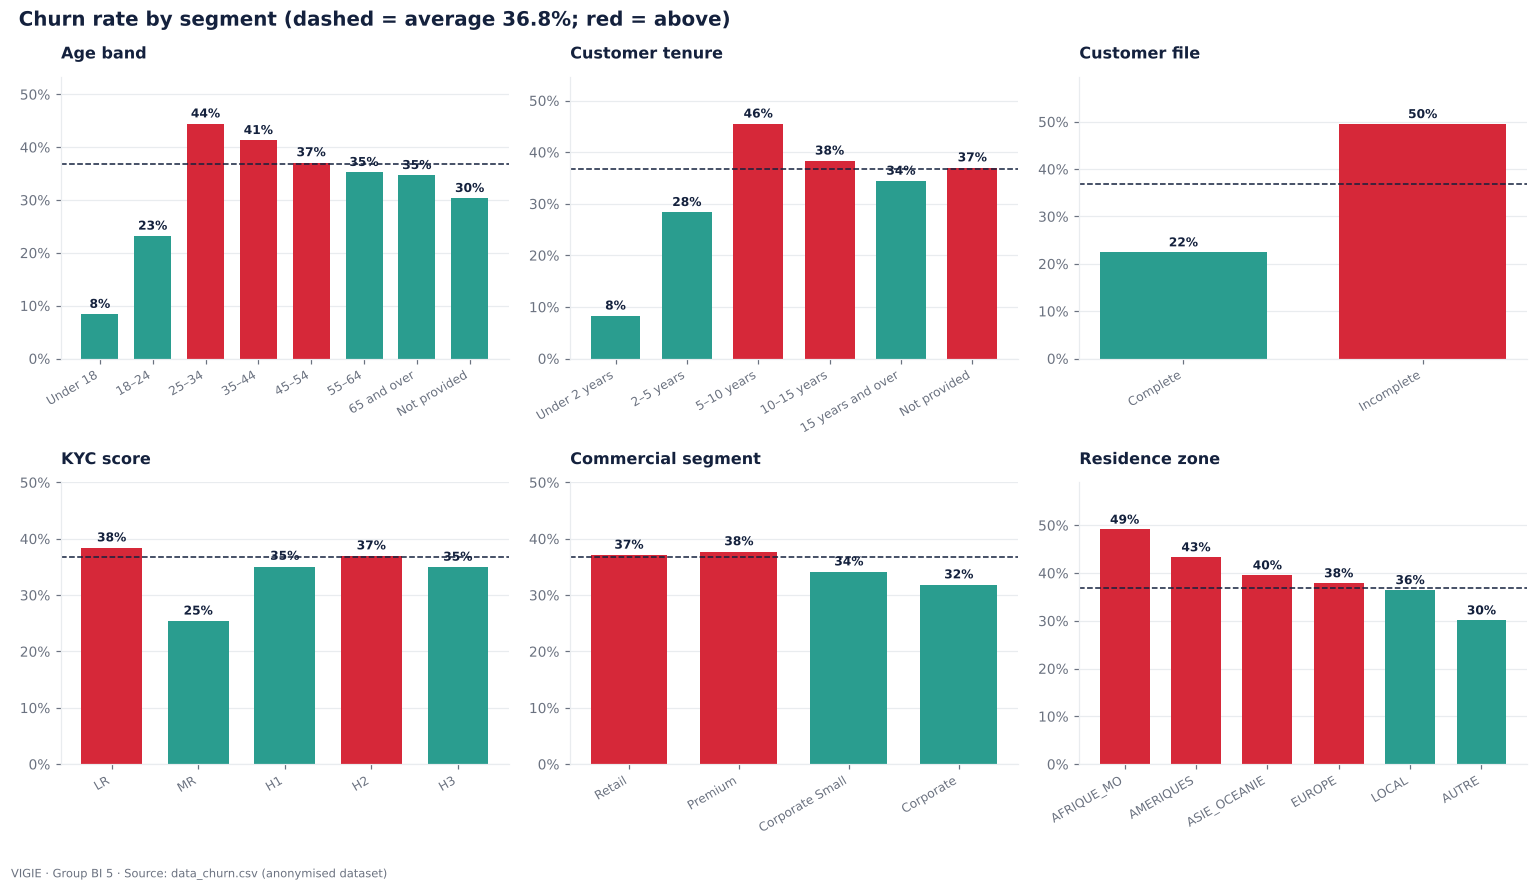

In [3]:
def churn_bars(ax, col, title, order=None, top=None):
    x = base[col].astype("object").where(base[col].notna(), data.NOT_PROVIDED)
    t = base.groupby(x)["CHURN"].agg(["mean", "size"])
    t = t[t["size"] >= config.MIN_CELL_SIZE]
    t = t.loc[[o for o in order if o in t.index]] if order else t.sort_values("mean", ascending=False)
    if top:
        t = t.head(top)
    colors = [C["churn"] if v > overall_rate else C["retention"] for v in t["mean"]]
    ax.bar(range(len(t)), t["mean"], color=colors, width=0.7)
    ax.axhline(overall_rate, color=C["ink"], ls="--", lw=1)
    for i, v in enumerate(t["mean"]):
        ax.text(i, v + 0.012, f"{v:.0%}", ha="center", fontsize=8, fontweight="bold", color=C["ink"])
    ax.set_xticks(range(len(t)))
    ax.set_xticklabels(t.index, rotation=30, ha="right", fontsize=8)
    ax.yaxis.set_major_formatter(style.percent)
    ax.set_ylim(0, max(t["mean"].max() * 1.2, 0.5))
    ax.set_title(title, fontsize=10.5)
    ax.grid(axis="x", visible=False)


age_order = data.AGE_BANDS + [data.NOT_PROVIDED]
tenure_order = data.TENURE_BANDS + [data.NOT_PROVIDED]
fig, axes = plt.subplots(2, 3, figsize=(14, 7.8))
churn_bars(axes[0, 0], "AGE_BAND", "Age band", age_order)
churn_bars(axes[0, 1], "TENURE_BAND", "Customer tenure", tenure_order)
churn_bars(axes[0, 2], "FILE_STATUS", "Customer file", ["Complete", "Incomplete"])
churn_bars(axes[1, 0], "SCORE_KYC", "KYC score", ["LR", "MR", "H1", "H2", "H3"])
churn_bars(axes[1, 1], "PARTYCLASS", "Commercial segment", ["Retail", "Premium", "Corporate Small", "Corporate"])
churn_bars(axes[1, 2], "RESIDENCE_REGION", "Residence zone")
fig.suptitle(f"Churn rate by segment (dashed = average {overall_rate:.1%}; red = above)", x=0.01, ha="left",
             fontweight="bold", color=C["ink"], fontsize=13)
fig.tight_layout()
style.save(fig, "02_bivariate_qualitative")
plt.show()

In [4]:
for col, order in [("AGE_BAND", age_order), ("TENURE_BAND", tenure_order), ("FILE_STATUS", None), ("SCORE_KYC", None)]:
    t = base.groupby(col)["CHURN"].agg(Customers="size", Churn_rate="mean")
    if order:
        t = t.loc[[o for o in order if o in t.index]]
    t["Churn_rate"] = t["Churn_rate"].map("{:.1%}".format)
    display(t)

,Customers,Churn_rate
AGE_BAND,,
Under 18,10067,8.4%
18–24,9054,23.2%
25–34,52602,44.4%
35–44,66685,41.3%
45–54,60413,37.1%
55–64,47878,35.2%
65 and over,52315,34.7%
Not provided,20026,30.3%


,Customers,Churn_rate
TENURE_BAND,,
Under 2 years,8478,8.3%
2–5 years,48508,28.4%
5–10 years,91424,45.5%
10–15 years,63124,38.3%
15 years and over,105653,34.4%
Not provided,1853,37.0%


,Customers,Churn_rate
FILE_STATUS,,
Complete,150750,22.5%
Incomplete,168290,49.6%


,Customers,Churn_rate
SCORE_KYC,,
H1,17170,35.1%
H2,9796,36.9%
H3,4099,34.9%
LR,256284,38.3%
MR,31649,25.3%


**Reading — qualitative variables**

* **Customer file**: this is the qualitative variable most strongly linked to churn (V = 0.28). A customer whose
  file is **incomplete** leaves more than twice as often (49.6%) as a customer whose file is complete (22.5%).
* **Age** and **tenure**: the link exists (V ≈ 0.15) but it is **not monotonic**. Churn peaks among 25–34 year
  olds (44%) and between 5 and 10 years of tenure (45.5%), then goes back down. Minors (8%) and customers of
  less than 2 years (8%) leave very little — for the latter, also because they have not had time to leave yet.
* **KYC score**: only the medium-risk score `MR` stands out (25% against 35–38% for the others).
* **Branch group**: a spread from 32% to 46% depending on the group — a useful axis for steering.
* **Segment, line of business, customer type, industry**: a very weak link (V ≤ 0.03). Churn affects every
  segment in a comparable way.

## 2. Quantitative variables × churn

The **univariate AUC** reads as follows: it is the probability that a customer who left has a higher value than
a customer who stayed. 0.5 = no separating power; the further from 0.5, the better the variable separates the
two groups.

In [5]:
quantitative = {
    "MONTHS_SINCE_REVIEW": "Months since last review", "MONTHS_TO_NEXT_REVIEW": "Months to next review",
    "CUSTOMER_TENURE": "Customer tenure (years)", "AGE": "Age", "N_ACCOUNTS": "Number of accounts",
    "SALARY": "Declared income",
}
rows = []
for col, lab in quantitative.items():
    s = base[[col, "CHURN"]].dropna()
    left, stayed = s.loc[s["CHURN"] == 1, col], s.loc[s["CHURN"] == 0, col]
    _, p = stats.mannwhitneyu(left, stayed)
    rows.append({
        "Variable": lab, "Customers with a value": len(s),
        "Median — stayed": round(stayed.median(), 1), "Median — left": round(left.median(), 1),
        "Univariate AUC": round(roc_auc_score(s["CHURN"], s[col]), 3),
        "Spearman ρ": round(stats.spearmanr(s[col], s["CHURN"])[0], 3),
        "Mann-Whitney p-value": f"{p:.1e}",
    })
quant_links = pd.DataFrame(rows).set_index("Variable")
quant_links["Distance to 0.5"] = (quant_links["Univariate AUC"] - 0.5).abs()
quant_links = quant_links.sort_values("Distance to 0.5", ascending=False).drop(columns="Distance to 0.5")
display(quant_links)

,Customers with a value,Median — stayed,Median — left,Univariate AUC,Spearman ρ,Mann-Whitney p-value
Variable,,,,,,
Months since last review,319015,36.6,60.6,0.672,0.288,0.0e+00
Months to next review,318980,8.4,-14.6,0.334,-0.277,0.0e+00
Declared income,104322,400.0,400.0,0.475,-0.045,5.2e-48
Number of accounts,319040,1.0,1.0,0.476,-0.066,1.5e-307
Age,299014,47.0,47.0,0.492,-0.014,1.5e-13
Customer tenure (years),317187,11.1,10.4,0.505,0.009,6.1e-07


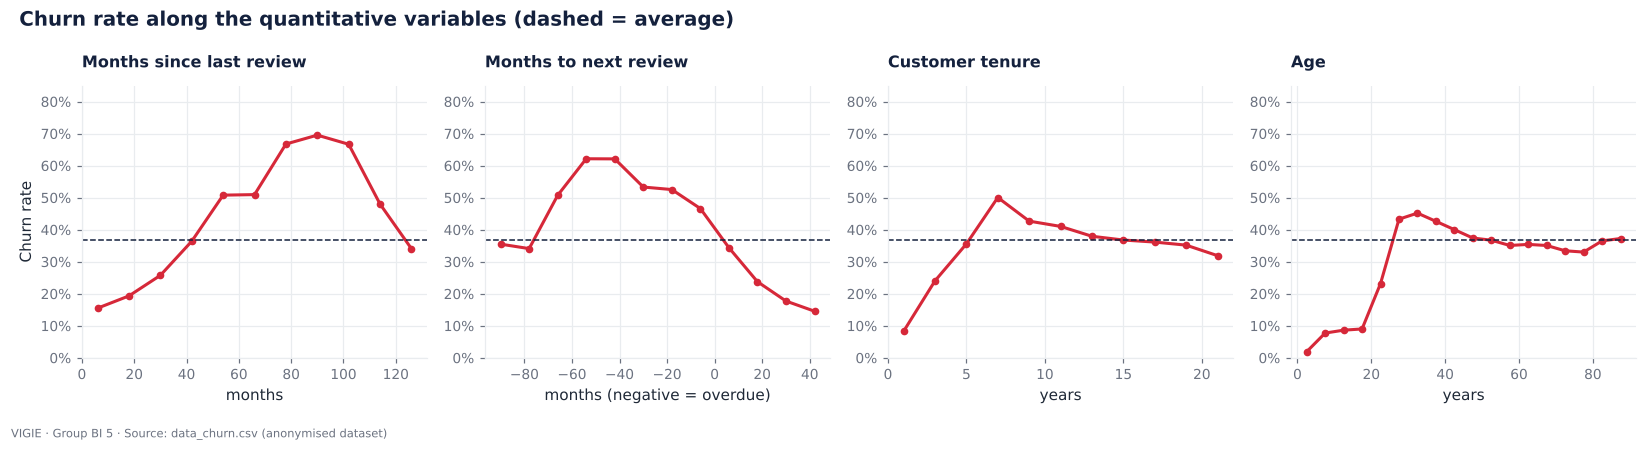

In [6]:
def churn_curve(ax, col, title, bins, unit=""):
    """Churn rate per band of a quantitative variable."""
    band = pd.cut(base[col], bins=bins)
    t = base.groupby(band, observed=True)["CHURN"].agg(["mean", "size"])
    t = t[t["size"] >= config.MIN_CELL_SIZE]
    x = [i.mid for i in t.index]
    ax.plot(x, t["mean"], color=C["churn"], marker="o", lw=2, ms=4)
    ax.axhline(overall_rate, color=C["ink"], ls="--", lw=1)
    ax.yaxis.set_major_formatter(style.percent)
    ax.set_ylim(0, 0.85)
    ax.set_title(title, fontsize=10.5)
    ax.set_xlabel(unit)


fig, axes = plt.subplots(1, 4, figsize=(15, 3.8))
churn_curve(axes[0], "MONTHS_SINCE_REVIEW", "Months since last review", list(range(0, 133, 12)), "months")
churn_curve(axes[1], "MONTHS_TO_NEXT_REVIEW", "Months to next review", list(range(-96, 61, 12)), "months (negative = overdue)")
churn_curve(axes[2], "CUSTOMER_TENURE", "Customer tenure", list(range(0, 26, 2)), "years")
churn_curve(axes[3], "AGE", "Age", list(range(0, 91, 5)), "years")
axes[0].set_ylabel("Churn rate")
fig.suptitle("Churn rate along the quantitative variables (dashed = average)", x=0.01, ha="left",
             fontweight="bold", color=C["ink"], fontsize=13)
fig.tight_layout()
style.save(fig, "02_bivariate_quantitative")
plt.show()

In [7]:
t = base.groupby(base["N_ACCOUNTS"].clip(upper=5))["CHURN"].agg(Customers="size", Churn_rate="mean")
t.index = [str(i) if i < 5 else "5 and more" for i in t.index]
t.index.name = "Number of accounts"
t["Churn_rate"] = t["Churn_rate"].map("{:.1%}".format)
display(t)

,Customers,Churn_rate
Number of accounts,,
1,273575,38.1%
2,27189,29.8%
3,8623,23.8%
4,4328,24.2%
5 and more,5325,36.6%


**Reading — quantitative variables**

* **File reviews**: these are the most separating variables. Among the customers who left, the last review is,
  at the median, **61 months** old (37 months among those who stayed) and the next review is **15 months
  overdue** (whereas it is due in 8 months among those who stayed). The churn rate climbs sharply as soon as
  the review is overdue.
* **Age and tenure**: their AUC is close to 0.5 although the bands in section 1 show a real effect. This is not
  a contradiction: the effect is **bell-shaped**, hence invisible to a monotonic measure. Practical
  consequence: a linear model will exploit them poorly, a tree-based model will exploit them well.
* **Number of accounts**: holding several products protects. 38% churn with a single account, 24% with three or four.
* **Declared income**: a very weak link, and the variable is blank for two customers out of three.

⚠ **Caution in interpretation.** A file that is not reviewed or incomplete may be a *cause* of the departure (a
neglected customer) but also a *consequence* (the file of a customer who has left is no longer reviewed). These
compliance variables are therefore kept, but their weight is measured separately in phase 4 (a "with / without"
sensitivity analysis).

## 3. Correlations between quantitative variables

**Spearman** correlation (ranks): suited to rounded, skewed variables.

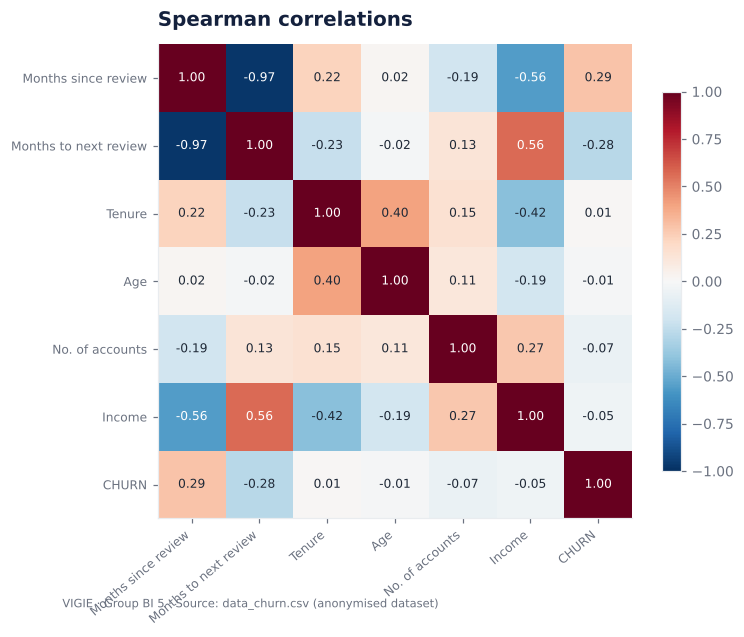

In [8]:
cols = list(quantitative) + ["CHURN"]
names = ["Months since review", "Months to next review", "Tenure", "Age", "No. of accounts", "Income", "CHURN"]
corr = base[cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(7, 5.6))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(names)))
ax.set_yticks(range(len(names)))
ax.set_xticklabels(names, rotation=40, ha="right", fontsize=8)
ax.set_yticklabels(names, fontsize=8)
for i in range(len(names)):
    for j in range(len(names)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(corr.iloc[i, j]) > 0.5 else C["text"])
ax.grid(False)
ax.set_title("Spearman correlations")
fig.colorbar(im, ax=ax, shrink=0.8)
style.save(fig, "02_bivariate_correlations")
plt.show()

The two review variables are strongly and negatively correlated with each other: they tell the same story (a
file reviewed long ago has an overdue next review). The other variables are weakly correlated with one another:
they bring complementary information.

## 4. Redundancy between qualitative variables

Two variables that are strongly linked to each other carry the same information: only one will be kept for modelling.

In [9]:
pairs = [("PARTYCLASS", "LOB"), ("RESIDENCE_REGION", "NATIONALITY_REGION"), ("NATURE_CLIENT", "PARTYCLASS"),
         ("NATURE_CLIENT", "INDUSTRY"), ("SCORE_KYC", "NATURE_CLIENT")]
redundancy = pd.DataFrame([{"Variable A": a, "Variable B": b,
                            "Cramér's V": round(cramers_v(base[a].fillna("NR"), base[b].fillna("NR"))[0], 3)}
                           for a, b in pairs])
display(redundancy)

,Variable A,Variable B,Cramér's V
0,PARTYCLASS,LOB,1.000
1,RESIDENCE_REGION,NATIONALITY_REGION,0.708
2,NATURE_CLIENT,PARTYCLASS,0.524
3,NATURE_CLIENT,INDUSTRY,0.580
4,SCORE_KYC,NATURE_CLIENT,0.400


`PARTYCLASS` and `LOB` are **strictly equivalent** (V = 1.00): only the commercial segment is kept.
Residence and nationality zones are strongly linked (V = 0.71): only residence is kept.

## 5. What about the account variables? A trap to avoid

One could cross churn with the account family, the currency or the balance. But these columns are **blank for
two closed accounts out of three** and never for active accounts: their mere presence tells us about the target.

In [10]:
trap = accounts.assign(ACCOUNT_INFO=np.where(accounts["ACCT_BALANCE"].isna(), "Blank balance", "Balance filled in"))
t = trap.groupby("ACCOUNT_INFO")["CHURN"].agg(Accounts="size", Churn_rate="mean")
t["Churn_rate"] = t["Churn_rate"].map("{:.1%}".format)
display(t)
v_leak, _ = cramers_v(trap["ACCOUNT_INFO"], trap["CHURN"])
print(f"Cramér's V between \"blank balance\" and churn: {v_leak:.3f}  (compare with the values of the table in section 1)")

,Accounts,Churn_rate
ACCOUNT_INFO,,
Balance filled in,309831,15.4%
Blank balance,100478,100.0%


Cramér's V between "blank balance" and churn: 0.757  (compare with the values of the table in section 1)


An account whose balance is blank is **always** closed. The link (V = 0.76) is out of all proportion to that of
the genuine explanatory variables: it is the signature of a **target leak**, not of a churn factor.
These columns are excluded from the modelling (phase 4).

## Summary

Ranking of all the variables by the strength of their link with churn. The two measures are on the same scale,
from 0 (no link) to 1 (perfect link).

In [11]:
ranking = pd.concat([
    qual_links[["Cramér's V"]].rename(columns={"Cramér's V": "Strength"}).assign(Measure="Cramér's V"),
    (quant_links["Univariate AUC"] - 0.5).abs().mul(2).round(3).to_frame("Strength").assign(Measure="|2·AUC − 1|"),
]).sort_values("Strength", ascending=False)
display(ranking)

,Strength,Measure
Variable,,
Months since last review,0.344,|2·AUC − 1|
Months to next review,0.332,|2·AUC − 1|
Customer file,0.280,Cramér's V
Tenure band,0.156,Cramér's V
Age band,0.144,Cramér's V
KYC score,0.081,Cramér's V
Branch group,0.065,Cramér's V
Declared income,0.050,|2·AUC − 1|
Number of accounts,0.048,|2·AUC − 1|


**What to remember for the next phases**

1. The **compliance** variables (file review, complete file) are by far the most strongly linked to churn.
2. **Age** and **tenure** have a bell-shaped effect: models able to capture non-linearity are needed.
3. **Holding several accounts** protects: single-account customers are the most fragile.
4. The **commercial segment** and the **industry** discriminate very little.
5. The account columns (balance, family, currency…) are a **target leak** and are not explanatory variables.